# 06 – Ayrılma Niyeti Tahmin Modeli (sızıntısız, adil karşılaştırmalı)

**Amaç:** Bir çalışanın anket cevaplarına bakarak "1 yıl içinde ayrılmayı düşünüyor mu?" sorusunu tahmin etmek ve **hangi modelin en uygun olduğunu** adil bir şekilde bulmak.

**Etiket (tahmin edilecek şey):** `y = 1` → ayrılmayı düşünüyor, `y = 0` → düşünmüyor (DLEAVING).

### Bu notebook'ta alınan önlemler

| Risk | Ne olabilirdi? | Burada ne yapıldı? |
|---|---|---|
| **Veri sızıntısı (leakage)** | Ölçekleme / eksik doldurma tüm veriye uygulanır, model test verisini "görür" | Tüm ön işleme bir `Pipeline` içinde; **yalnızca eğitim verisine** `fit` edilir. Test seti en başta ayrılır, ID'leri kaydedilir ve **sadece bir kez**, en sonda kullanılır |
| **Hedef sızıntısı** | Etiketle neredeyse aynı şeyi ölçen sorular modele girer | Q46, Q70, Q72 (genel memnuniyet) çıkarıldı; ayrıca her özellik için otomatik "şüpheli derecede güçlü mü?" taraması yapılır |
| **Yanlış özellikler** | ID, ağırlık gibi sütunlar özellik olarak kullanılır | `RandomID`, `POSTWT` özellik listesinde yok – `assert` ile kontrol edilir. Ağırlık yalnızca `sample_weight` olarak kullanılır |
| **Kategorik kodu sayı sanmak** | Ajans kodu / demografik harfler sayı gibi işlenir | Kategorikler `OneHotEncoder` ile kodlanır. Likert (1–5) sıralı olduğu için sayısal tutulur – bilinçli karar |
| **Hataları gizlemek** | `dropna()` ile satırlar sessizce silinir | Her adımda satır/kolon sayısı yazdırılır. Silinen tek satır grubu: etiketi boş olanlar (sayısı raporlanır). `try/except` yok, uyarılar kapatılmadı |
| **Test setinde ayar yapmak** | Hiperparametreler test sonucuna bakılarak seçilir | Ayar ve model seçimi yalnızca eğitim verisi içinde **çapraz doğrulama (CV)** ile yapılır |
| **Adaletsiz karşılaştırma** | Bir model ayarlanır, diğerleri varsayılan kalır | Her modele **eşit ayar bütçesi** (aynı sayıda deneme, aynı CV katları, aynı veri) |
| **Abartılı başarı** | "Model harika" denir ama basit bir kuraldan iyi değildir | İki baseline ile karşılaştırma: (1) her zaman ortalamayı tahmin eden model, (2) tek soruluk basit kural |
| **Rastgelelik** | Her çalıştırmada farklı sonuç | Tek bir `SEED = 42`, her yerde kullanılır |
| **Eğitim–tahmin tutarsızlığı** | Tahmin kodunda farklı ön işleme | Özellik hazırlığı tek fonksiyonda (`hazirla`), ön işleme + model tek `Pipeline`, diske kaydedilir ve geri yüklenip **aynı sonucu verdiği test edilir** |
| **Gereksiz karmaşıklık** | Çok dosyalı, takip edilemeyen yapı | Tek notebook, adım adım, her adımın açıklaması var |

## 0. Kurulum

In [1]:
import json, time, hashlib
from pathlib import Path
from textwrap import fill
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import lightgbm as lgb
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, ParameterSampler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, log_loss,
                             precision_score, recall_score, f1_score, accuracy_score, roc_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from scipy.stats import loguniform
from IPython.display import display

SEED = 42
np.random.seed(SEED)
print("Sürümler → pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| lightgbm", lgb.__version__)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA, FIG, TAB, MODELS = ROOT / "data", ROOT / "reports" / "figures", ROOT / "reports" / "tables", ROOT / "models"
for d in (FIG, TAB, MODELS):
    d.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Segoe UI", "DejaVu Sans"],
                     "font.size": 10, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": AXIS, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": INK2, "axes.labelcolor": INK2,
                     "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True})

def kaydet(ad):
    plt.savefig(FIG / f"{ad}.png", dpi=110, bbox_inches="tight"); plt.show()

def log(adim, d):
    """Her adımda satır/kolon sayısını yazdırır – sessiz veri kaybını yakalamak için."""
    print(f"[{adim:<38}] satır = {len(d):>9,}" + (f"   kolon = {d.shape[1]}" if getattr(d, "ndim", 1) > 1 else ""))

Sürümler → pandas 3.0.1 | scikit-learn 1.8.0 | lightgbm 4.6.0


## 1. Veriyi yükle ve etiketi oluştur
Etiketi (DLEAVING) boş olan satırlar modele giremez: cevabını bilmediğimiz bir şeyi öğretemeyiz. Bu satırlar **sayılarak** çıkarılır.

In [2]:
df = pd.read_pickle(DATA / "fevs2024_clean.pkl")
cb = pd.read_excel(DATA / "2024" / "2024_OPM_FEVS_PRDF_Codebook.xlsx", sheet_name="Survey Items")
cb["VARIABLE"] = cb["VARIABLE"].str.strip()
text_map = cb.groupby("VARIABLE")["ITEM TEXT"].first().str.strip().to_dict()
log("Ham veri", df)

etiketsiz = df["DLEAVING"].isna().sum()
df = df[df["DLEAVING"].notna()].copy()
print(f"Etiketi boş olduğu için çıkarılan satır: {etiketsiz:,} (%{100 * etiketsiz / (len(df) + etiketsiz):.1f})")
log("Etiketli veri", df)

y_all = (df["DLEAVING"] != "No").astype(int).rename("y")
w_all = df["POSTWT"]
print(f"Ayrılmayı düşünenlerin oranı: ağırlıksız %{100 * y_all.mean():.1f}, ağırlıklı %{100 * np.average(y_all, weights=w_all):.1f}")

[Ham veri                              ] satır =   674,207   kolon = 98


Etiketi boş olduğu için çıkarılan satır: 41,909 (%6.2)
[Etiketli veri                         ] satır =   632,298   kolon = 98
Ayrılmayı düşünenlerin oranı: ağırlıksız %33.8, ağırlıklı %36.8


## 2. Özellikleri seç ve hazırla

| Grup | Sütunlar | Neden? |
|---|---|---|
| Likert soruları (sayısal, 1–5) | 73 soru | Ana bilgi kaynağı |
| Q16 (0/1) | 6 sütun | "Düşük performanslılara ne oluyor?" |
| Kategorik | ajans, Q91 (tele-çalışma), 8 demografik değişken | Bağlam; **DAGEGRP kuşak analizinin temeli** |
| **Çıkarılanlar** | RandomID, POSTWT, DLEAVING, level1, Q46, Q70, Q72 | ID / ağırlık / etiketin kendisi / çok yüksek kardinalite / hedefle neredeyse eş anlamlı sorular |

`hazirla()` fonksiyonu **satır bazında** çalışır (hiçbir istatistik hesaplamaz), bu yüzden bölmeden önce uygulanması sızıntı yaratmaz. Aynı fonksiyon tahmin (inference) sırasında da kullanılır.

In [3]:
Q16_COLS = [f"Q16_{i}" for i in range(1, 7)]
LIKERT = [c for c in df.columns if c.startswith("Q") and c not in Q16_COLS and c != "Q91"]
PROXY = ["Q46", "Q70", "Q72"]
NUM = [q for q in LIKERT if q not in PROXY] + Q16_COLS
CAT = ["agency", "Q91", "DRNO", "DHISP", "DDIS", "DAGEGRP", "DSUPER", "DFEDTEN", "DSEX", "DMIL"]
FEATURES = NUM + CAT
YASAK = ["RandomID", "POSTWT", "DLEAVING", "level1", "level1_name", "agency_name"] + PROXY

def hazirla(d, num=NUM, cat=CAT):
    """Ham veriden model girdisini üretir. Satır bazında – istatistik öğrenmez, sızıntı yaratmaz.
    Kategorikler kısa kodlara çevrilir (ör. 'A', 'B'); eksik değer NaN kalır, pipeline içinde ele alınır."""
    X = d[num].astype("float32")
    for c in cat:
        s = d[c]
        if c == "agency":
            X[c] = s.astype(str)
        else:
            X[c] = s.cat.codes.astype(str).where(s.notna(), np.nan)   # 0,1,2… ; eksik = NaN
        X[c] = X[c].astype(object)
    return X

X_all = hazirla(df)
log("Özellik matrisi", X_all)
assert not set(YASAK) & set(X_all.columns), "Yasaklı sütun özelliklerde!"
assert len(X_all) == len(y_all) == len(w_all)
print(f"Sayısal: {len(NUM)}  Kategorik: {len(CAT)}  Toplam: {X_all.shape[1]}")

# Kuşak (yalnızca analiz için – model DAGEGRP'yi zaten özellik olarak görüyor)
KUSAK = df["DAGEGRP"].map({"Under 40": "Genç kuşak (<40: Y/Z)", "40 or Older": "Olgun kuşak (40+: X/Boomer)"}) \
          .astype(object).fillna("Bilinmiyor (maskeli)")

[Özellik matrisi                       ] satır =   632,298   kolon = 89
Sayısal: 79  Kategorik: 10  Toplam: 89


## 3. Test setini ayır ve **dondur**
Verinin %20'si en başta ayrılır. Bu kısım ayar, model seçimi, eşik seçimi gibi hiçbir kararda kullanılmaz; yalnızca en sonda bir kez "final sınav" olarak kullanılır.
Bölme **katmanlı** (stratified) yapılır: ayrılma oranı iki parçada aynı kalır.
Bu veri tek bir yılın kesitsel anketidir (zaman serisi değildir), bu yüzden rastgele bölme uygundur.

In [4]:
idx_tr, idx_te = train_test_split(X_all.index, test_size=0.20, stratify=y_all, random_state=SEED)
X_tr, X_te = X_all.loc[idx_tr], X_all.loc[idx_te]
y_tr, y_te = y_all.loc[idx_tr], y_all.loc[idx_te]
w_tr, w_te = w_all.loc[idx_tr], w_all.loc[idx_te]
log("Eğitim (train)", X_tr); log("Test (dondurulmuş)", X_te)

test_ids = df.loc[idx_te, "RandomID"].sort_values()
test_ids.to_csv(DATA / "test_ids.csv", index=False)
TEST_HASH = hashlib.sha256("".join(test_ids).encode()).hexdigest()[:16]
print("Test seti parmak izi (SHA-256):", TEST_HASH)

assert set(df.loc[idx_tr, "RandomID"]).isdisjoint(set(test_ids)), "Train ve test kesişiyor!"
print(f"Ayrılma oranı – train: %{100 * y_tr.mean():.2f}  test: %{100 * y_te.mean():.2f}")

[Eğitim (train)                        ] satır =   505,838   kolon = 89
[Test (dondurulmuş)                    ] satır =   126,460   kolon = 89


Test seti parmak izi (SHA-256): 08e7e1093d3d3350


Ayrılma oranı – train: %33.82  test: %33.82


## 4. Sızıntı taraması – şüpheli derecede güçlü özellik var mı?
Her sayısal özellik **tek başına** etiketi ne kadar iyi tahmin ediyor? (Yalnızca eğitim verisinde.) Tek bir soru tek başına çok yüksek AUC veriyorsa, o soru etiketin "kopyası" olabilir.
Eşik: AUC > 0,75 → şüpheli. Karşılaştırma için çıkarılan Q46/Q70/Q72 de gösterilir.

In [5]:
def tek_auc(x, y, w):
    m = x.notna()
    a = roc_auc_score(y[m], -x[m], sample_weight=w[m])     # yüksek puan → düşük ayrılma, işaret çevrilir
    return max(a, 1 - a)

tarama = pd.Series({c: tek_auc(X_tr[c], y_tr, w_tr) for c in NUM}, name="tek_başına_AUC").sort_values(ascending=False)
proxy_tr = df.loc[idx_tr, PROXY].astype("float32")
proxy_auc = pd.Series({c: tek_auc(proxy_tr[c], y_tr, w_tr) for c in PROXY}, name="tek_başına_AUC")
print("Çıkarılan sorular (karşılaştırma için):"); display(proxy_auc.round(3).to_frame().assign(soru=lambda d: d.index.map(text_map)))
print("Modeldeki en güçlü 8 özellik:"); display(tarama.head(8).round(3).to_frame().assign(soru=lambda d: d.index.map(text_map)))
supheli = tarama[tarama > 0.75]
print("Şüpheli (AUC > 0,75) özellik sayısı:", len(supheli))
assert supheli.empty, f"Olası hedef sızıntısı: {list(supheli.index)}" 

Çıkarılan sorular (karşılaştırma için):


,tek_başına_AUC,soru
Q46,0.725,I recommend my organization as a good place to...
Q70,0.742,"Considering everything, how satisfied are you ..."
Q72,0.734,"Considering everything, how satisfied are you ..."


Modeldeki en güçlü 8 özellik:


,tek_başına_AUC,soru
Q86,0.696,My job inspires me.
Q88,0.696,I feel a strong personal attachment to my orga...
Q67,0.690,How satisfied are you with your involvement in...
Q6,0.690,My talents are used well in the workplace.
Q47,0.688,I believe the results of this survey will be u...
Q69,0.686,How satisfied are you with the recognition you...
Q68,0.683,How satisfied are you with the information you...
Q65,0.681,Management makes effective changes to address ...


Şüpheli (AUC > 0,75) özellik sayısı: 0


## 5. Modeller ve ön işleme hatları (Pipeline)

**Ön işleme her modelin içinde** – böylece CV'nin her katında ve final eğitimde yalnızca o anki eğitim verisine fit edilir.
- **Doğrusal model (lojistik regresyon):** eksik sayılar → medyan + "eksik miydi?" göstergesi, sonra ölçekleme.
- **Ağaç modelleri:** eksik değerleri kendileri işleyebildiği için sayılar olduğu gibi bırakılır.
- **Kategorikler (hepsi):** eksik → "Eksik" kategorisi (maskelenmiş demografi bilgi taşıyor, 02 notebook'u), sonra one-hot.

| Model | Ne tür? | Basitçe |
|---|---|---|
| Baseline – ortalama | Kukla | Herkese aynı olasılığı (%37) verir. Bunu geçemeyen model işe yaramaz |
| Baseline – tek soru (Q88) | Basit kural | Sadece "kuruma bağlılık" sorusuna bakar |
| Lojistik regresyon | Doğrusal | Her soruya bir ağırlık verir ve toplar. Yorumlaması en kolay |
| Random Forest | Ağaç topluluğu | Yüzlerce karar ağacı oylar |
| HistGradientBoosting | Boosting | Ağaçları sırayla, bir öncekinin hatasını düzelterek kurar (scikit-learn) |
| LightGBM | Boosting | Aynı fikir, çok hızlı ve popüler bir kütüphane |

In [6]:
def onisleme(dogrusal):
    num = (Pipeline([("eksik", SimpleImputer(strategy="median", add_indicator=True)), ("olcek", StandardScaler())])
           if dogrusal else "passthrough")
    cat = Pipeline([("eksik", SimpleImputer(strategy="constant", fill_value="Eksik")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, NUM), ("cat", cat, CAT)])

MODELLER = {
    "Baseline: ortalama": (Pipeline([("prep", onisleme(False)), ("clf", DummyClassifier(strategy="prior"))]), None),
    "Baseline: tek soru (Q88)": (Pipeline([("prep", ColumnTransformer([("q", SimpleImputer(strategy="median"), ["Q88"])])),
                                           ("clf", LogisticRegression())]), None),
    "Lojistik regresyon": (Pipeline([("prep", onisleme(True)), ("clf", LogisticRegression(max_iter=3000))]),
                           {"clf__C": loguniform(1e-3, 10)}),
    "Random Forest": (Pipeline([("prep", onisleme(False)),
                                ("clf", RandomForestClassifier(n_estimators=200, n_jobs=4, random_state=SEED))]),
                      {"clf__max_depth": [12, 16, 20], "clf__min_samples_leaf": [20, 50, 100],
                       "clf__max_features": ["sqrt", 0.2, 0.4], "clf__max_samples": [0.3, 0.5]}),
    "HistGradientBoosting": (Pipeline([("prep", onisleme(False)),
                                       ("clf", HistGradientBoostingClassifier(early_stopping=False, random_state=SEED))]),
                             {"clf__learning_rate": loguniform(0.03, 0.3), "clf__max_iter": [200, 400, 600],
                              "clf__max_leaf_nodes": [15, 31, 63], "clf__min_samples_leaf": [20, 100, 300],
                              "clf__l2_regularization": [0.0, 1.0, 10.0]}),
    "LightGBM": (Pipeline([("prep", onisleme(False)),
                           ("clf", lgb.LGBMClassifier(subsample_freq=1, n_jobs=4, random_state=SEED, verbose=-1))]),
                 {"clf__learning_rate": loguniform(0.02, 0.2), "clf__n_estimators": [200, 400, 700],
                  "clf__num_leaves": [15, 31, 63, 127], "clf__min_child_samples": [20, 100, 300],
                  "clf__subsample": [0.7, 0.85, 1.0], "clf__colsample_bytree": [0.5, 0.7, 0.9],
                  "clf__reg_lambda": [0.0, 1.0, 10.0]}),
}
KARMASIKLIK_SIRASI = ["Lojistik regresyon", "Random Forest", "HistGradientBoosting", "LightGBM"]   # basitten karmaşığa

## 6. Adil hiperparametre ayarı – **eşit bütçe**
Her model için:
- aynı **ayar örneklemi** (eğitim setinden 60 bin satır, sabit seed),
- aynı **3 katlı katmanlı CV** (aynı katlar),
- aynı sayıda deneme (**12 rastgele parametre kombinasyonu**),
- aynı ölçüt: **ağırlıklı ROC-AUC**.

Test seti burada hiç kullanılmaz. Örneklem kullanılması zaman kazandırır; en iyi ayarlar sonra tüm eğitim setiyle yeniden eğitilir.
Not: Örneklem ve kat ayrımı sadece `idx_tr` içinden yapılır (aşağıda `assert` ile kontrol edilir).

In [7]:
N_TUNE, N_ITER, N_FOLD = 60_000, 12, 3
idx_tune, _ = train_test_split(idx_tr, train_size=N_TUNE, stratify=y_tr, random_state=SEED)
assert set(idx_tune) <= set(idx_tr) and set(idx_tune).isdisjoint(idx_te)
Xt, yt, wt = X_tr.loc[idx_tune], y_tr.loc[idx_tune], w_tr.loc[idx_tune]
log("Ayar örneklemi", Xt)
FOLDS = list(StratifiedKFold(N_FOLD, shuffle=True, random_state=SEED).split(Xt, yt))

def cv_auc(pipe, X, y, w, folds):
    skorlar = []
    for tr, va in folds:
        m = clone(pipe).fit(X.iloc[tr], y.iloc[tr], clf__sample_weight=w.iloc[tr].values)
        skorlar.append(roc_auc_score(y.iloc[va], m.predict_proba(X.iloc[va])[:, 1], sample_weight=w.iloc[va]))
    return np.mean(skorlar), np.std(skorlar)

ayar_kaydi, en_iyi = [], {}
for ad, (pipe, alan) in MODELLER.items():
    t0 = time.time()
    adaylar = [{}] if alan is None else list(ParameterSampler(alan, n_iter=N_ITER, random_state=SEED))
    for i, p in enumerate(adaylar):
        ort, ss = cv_auc(clone(pipe).set_params(**p), Xt, yt, wt, FOLDS)
        ayar_kaydi.append({"model": ad, "deneme": i, "cv_auc": ort, "cv_ss": ss, "parametreler": p})
    kayit = pd.DataFrame([r for r in ayar_kaydi if r["model"] == ad])
    b = kayit.loc[kayit["cv_auc"].idxmax()]
    en_iyi[ad] = {"parametreler": b["parametreler"], "cv_auc": b["cv_auc"], "cv_ss": b["cv_ss"],
                  "deneme_sayisi": len(adaylar), "sure_sn": time.time() - t0}
    print(f"{ad:<26} deneme={len(adaylar):>2}  en iyi CV AUC = {b['cv_auc']:.4f} ± {b['cv_ss']:.4f}   ({time.time() - t0:,.0f} sn)")

ayar_df = pd.DataFrame(ayar_kaydi)
ayar_df.assign(parametreler=ayar_df["parametreler"].astype(str)).to_csv(TAB / "06_ayar_kaydi.csv", index=False)

[Ayar örneklemi                        ] satır =    60,000   kolon = 89


Baseline: ortalama         deneme= 1  en iyi CV AUC = 0.5000 ± 0.0000   (2 sn)


Baseline: tek soru (Q88)   deneme= 1  en iyi CV AUC = 0.6895 ± 0.0048   (0 sn)


Lojistik regresyon         deneme=12  en iyi CV AUC = 0.7695 ± 0.0039   (114 sn)


Random Forest              deneme=12  en iyi CV AUC = 0.7686 ± 0.0029   (470 sn)


...

~\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


~\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


~\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


~\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM                   deneme=12  en iyi CV AUC = 0.7794 ± 0.0035   (243 sn)


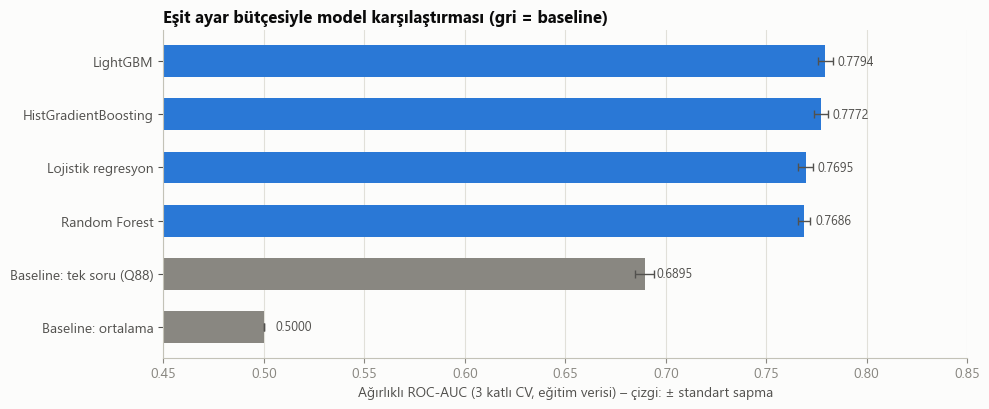

,cv_auc,cv_ss,deneme_sayisi,sure_sn
Baseline: ortalama,0.5000,0.0000,1.0,1.9232
Baseline: tek soru (Q88),0.6895,0.0048,1.0,0.3973
Random Forest,0.7686,0.0029,12.0,469.9596
Lojistik regresyon,0.7695,0.0039,12.0,113.6918
HistGradientBoosting,0.7772,0.0033,12.0,717.5296
LightGBM,0.7794,0.0035,12.0,242.7678


In [8]:
cv_tab = pd.DataFrame(en_iyi).T[["cv_auc", "cv_ss", "deneme_sayisi", "sure_sn"]].astype(float)
cv_tab = cv_tab.sort_values("cv_auc")
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(cv_tab.index, cv_tab["cv_auc"], xerr=cv_tab["cv_ss"], color=[MUTED if "Baseline" in i else SERIES[0] for i in cv_tab.index],
        height=0.6, error_kw=dict(ecolor=INK2, lw=1, capsize=3))
for yy, v in enumerate(cv_tab["cv_auc"]):
    ax.text(v + 0.006, yy, f"{v:.4f}", va="center", fontsize=9, color=INK2)
ax.set_xlim(0.45, 0.85); ax.grid(axis="y", visible=False)
ax.set_xlabel("Ağırlıklı ROC-AUC (3 katlı CV, eğitim verisi) – çizgi: ± standart sapma")
ax.set_title("Eşit ayar bütçesiyle model karşılaştırması (gri = baseline)")
plt.tight_layout(); kaydet("06_01_cv_karsilastirma")
cv_tab.round(4)

## 7. Model seçimi – **test setine bakmadan**
Kural: CV AUC'si en yüksek model seçilir. Ancak daha basit bir model en iyinin **1 standart sapma** yakınındaysa (fark istatistiksel olarak anlamsız), **basit olan tercih edilir** ("bir standart hata kuralı"). Basit model daha hızlıdır, daha kolay açıklanır ve daha az hata saklar.

In [9]:
aday = {k: v for k, v in en_iyi.items() if k in KARMASIKLIK_SIRASI}
lider = max(aday, key=lambda k: aday[k]["cv_auc"])
esik = aday[lider]["cv_auc"] - aday[lider]["cv_ss"]
SECILEN = next(k for k in KARMASIKLIK_SIRASI if aday[k]["cv_auc"] >= esik)
print(f"CV lideri: {lider} ({aday[lider]['cv_auc']:.4f}); 1-SS eşiği: {esik:.4f}")
print(f"SEÇİLEN MODEL: {SECILEN}  (CV AUC {aday[SECILEN]['cv_auc']:.4f})")
print("Parametreler:", aday[SECILEN]["parametreler"])

CV lideri: LightGBM (0.7794); 1-SS eşiği: 0.7759
SEÇİLEN MODEL: HistGradientBoosting  (CV AUC 0.7772)
Parametreler: {'clf__l2_regularization': 10.0, 'clf__learning_rate': np.float64(0.044718364155969796), 'clf__max_iter': 200, 'clf__max_leaf_nodes': 31, 'clf__min_samples_leaf': 100}


## 8. Tüm modelleri tam eğitim setiyle yeniden eğit
Her model, kendi en iyi ayarlarıyla **tüm eğitim setinde** (≈505 bin satır) eğitilir. Test seti hâlâ kullanılmadı.

In [10]:
final = {}
for ad, (pipe, _) in MODELLER.items():
    t0 = time.time()
    final[ad] = clone(pipe).set_params(**en_iyi[ad]["parametreler"]).fit(X_tr, y_tr, clf__sample_weight=w_tr.values)
    print(f"{ad:<26} eğitildi ({time.time() - t0:,.0f} sn)")

Baseline: ortalama         eğitildi (6 sn)


Baseline: tek soru (Q88)   eğitildi (1 sn)


Lojistik regresyon         eğitildi (35 sn)


Random Forest              eğitildi (486 sn)


HistGradientBoosting       eğitildi (83 sn)


LightGBM                   eğitildi (63 sn)


## 9. Karar eşiğini seç – yine eğitim verisinde
Model bir olasılık verir (ör. %62). "Ayrılacak" demek için bir eşik gerekir. Eşik **test setinde değil**, eğitim verisinde 3 katlı CV ile üretilen "katlama dışı" (out-of-fold) tahminlerde, ağırlıklı F1'i en yüksek yapan değer olarak seçilir.

In [11]:
oof = pd.Series(np.nan, index=idx_tr)
for tr, va in StratifiedKFold(3, shuffle=True, random_state=SEED).split(X_tr, y_tr):
    m = clone(final[SECILEN]).fit(X_tr.iloc[tr], y_tr.iloc[tr], clf__sample_weight=w_tr.iloc[tr].values)
    oof.iloc[va] = m.predict_proba(X_tr.iloc[va])[:, 1]
assert oof.notna().all()
esikler = np.arange(0.15, 0.70, 0.01)
f1s = [f1_score(y_tr, (oof >= t).astype(int), sample_weight=w_tr) for t in esikler]
ESIK = float(esikler[int(np.argmax(f1s))])
print(f"Seçilen eşik: {ESIK:.2f}  (OOF ağırlıklı F1 = {max(f1s):.4f};  0,50 eşiğinde F1 = {f1_score(y_tr, (oof >= 0.5).astype(int), sample_weight=w_tr):.4f})")

Seçilen eşik: 0.32  (OOF ağırlıklı F1 = 0.6500;  0,50 eşiğinde F1 = 0.6032)


## 10. Final sınav – test seti (**tek seferlik**)
Bütün kararlar verildi. Şimdi tüm modeller dondurulmuş test setinde **bir kez** değerlendirilir. Bu sonuçlara bakılarak hiçbir şey değiştirilmez.

**Metrikler – basitçe:**
- **ROC-AUC:** Rastgele seçilen bir "ayrılacak" ve bir "kalacak" çalışandan, modelin ayrılacak olana daha yüksek risk verme olasılığı. 0,5 = yazı-tura, 1,0 = mükemmel.
- **PR-AUC:** Model "ayrılacak" dediğinde ne kadar haklı ve ayrılacakların ne kadarını yakalıyor (tek sayıda özet). Baseline değeri = ayrılma oranı (≈0,37).
- **Brier skoru:** Tahmin edilen olasılıkla gerçek sonuç arasındaki ortalama kare hata. **Düşük olan iyi.**
- **%95 güven aralığı:** Test setinden 200 kez yeniden örnekleme (bootstrap) ile AUC'nin ne kadar oynayabileceği.

In [12]:
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(y_te), len(y_te)) for _ in range(200)]
yv, wv = y_te.values, w_te.values
test_sonuc, test_tahmin = {}, {}
for ad, m in final.items():
    p = m.predict_proba(X_te)[:, 1]
    test_tahmin[ad] = p
    auc = roc_auc_score(yv, p, sample_weight=wv)
    boots = [roc_auc_score(yv[b], p[b], sample_weight=wv[b]) for b in boot_idx] if "ortalama" not in ad else [0.5]
    test_sonuc[ad] = {"ROC_AUC": auc, "AUC_%95_alt": np.percentile(boots, 2.5), "AUC_%95_üst": np.percentile(boots, 97.5),
                      "PR_AUC": average_precision_score(yv, p, sample_weight=wv),
                      "Brier": brier_score_loss(yv, p, sample_weight=wv), "LogLoss": log_loss(yv, p, sample_weight=wv),
                      "CV_AUC": en_iyi[ad]["cv_auc"]}
test_tab = pd.DataFrame(test_sonuc).T.sort_values("ROC_AUC", ascending=False)
test_tab.round(4).to_csv(TAB / "06_test_sonuclari.csv")
test_tab.round(4)

~\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,ROC_AUC,AUC_%95_alt,AUC_%95_üst,PR_AUC,Brier,LogLoss,CV_AUC
LightGBM,0.7910,0.7881,0.7937,0.7031,0.1742,0.5243,0.7794
HistGradientBoosting,0.7910,0.7880,0.7937,0.7027,0.1742,0.5244,0.7772
Random Forest,0.7828,0.7797,0.7856,0.6903,0.1778,0.5334,0.7686
Lojistik regresyon,0.7803,0.7773,0.7831,0.6877,0.1782,0.5352,0.7695
Baseline: tek soru (Q88),0.6952,0.6913,0.6993,0.5589,0.2019,0.5920,0.6895
Baseline: ortalama,0.5000,0.5000,0.5000,0.3686,0.2327,0.6582,0.5000


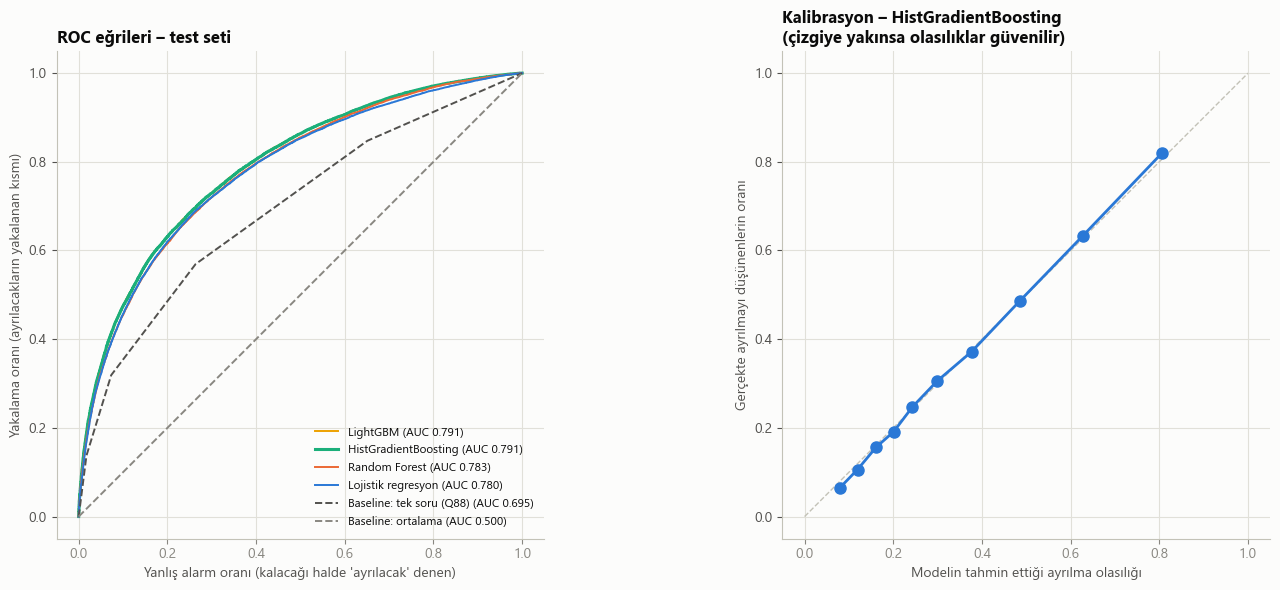

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sirali = [k for k in test_tab.index]
renk = {ad: SERIES[i] for i, ad in enumerate([k for k in MODELLER if "Baseline" not in k])}
renk.update({"Baseline: ortalama": MUTED, "Baseline: tek soru (Q88)": INK2})
for ad in sirali:
    fpr, tpr, _ = roc_curve(yv, test_tahmin[ad], sample_weight=wv)
    ls = "--" if "Baseline" in ad else "-"
    axes[0].plot(fpr, tpr, color=renk[ad], lw=2.2 if ad == SECILEN else 1.4, ls=ls,
                 label=f"{ad} (AUC {test_tab.loc[ad, 'ROC_AUC']:.3f})")
axes[0].set_xlabel("Yanlış alarm oranı (kalacağı halde 'ayrılacak' denen)")
axes[0].set_ylabel("Yakalama oranı (ayrılacakların yakalanan kısmı)")
axes[0].legend(frameon=False, fontsize=8.5, loc="lower right"); axes[0].set_title("ROC eğrileri – test seti")
axes[0].set_aspect("equal")

pt, pp = calibration_curve(yv, test_tahmin[SECILEN], n_bins=10, strategy="quantile")
axes[1].plot([0, 1], [0, 1], color=AXIS, ls="--", lw=1)
axes[1].plot(pp, pt, color=SERIES[0], lw=2, marker="o", ms=8)
axes[1].set_xlabel("Modelin tahmin ettiği ayrılma olasılığı"); axes[1].set_ylabel("Gerçekte ayrılmayı düşünenlerin oranı")
axes[1].set_title(f"Kalibrasyon – {SECILEN}\n(çizgiye yakınsa olasılıklar güvenilir)"); axes[1].set_aspect("equal")
plt.tight_layout(); kaydet("06_02_roc_kalibrasyon")

,eşik 0.32 (eğitimde seçilen),eşik 0.50,Baseline: herkese 'kalır'
Doğruluk (accuracy),0.708,0.745,0.631
Kesinlik (precision),0.582,0.703,0.000
Duyarlılık (recall),0.737,0.531,0.000
F1,0.650,0.605,0.000


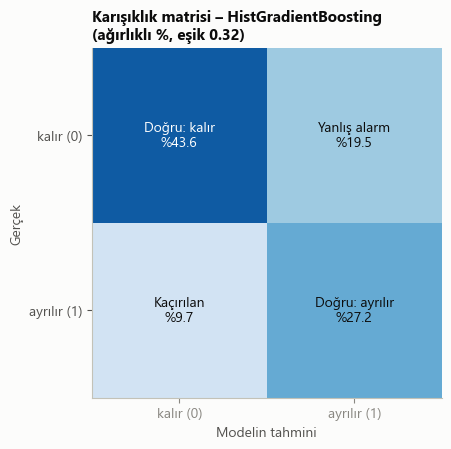

In [14]:
p_sec = test_tahmin[SECILEN]
tahmin = (p_sec >= ESIK).astype(int)
esik_tab = pd.DataFrame({
    f"eşik {ESIK:.2f} (eğitimde seçilen)": [accuracy_score(yv, tahmin, sample_weight=wv), precision_score(yv, tahmin, sample_weight=wv),
                                         recall_score(yv, tahmin, sample_weight=wv), f1_score(yv, tahmin, sample_weight=wv)],
    "eşik 0.50": [accuracy_score(yv, p_sec >= .5, sample_weight=wv), precision_score(yv, p_sec >= .5, sample_weight=wv),
                  recall_score(yv, p_sec >= .5, sample_weight=wv), f1_score(yv, p_sec >= .5, sample_weight=wv)],
    "Baseline: herkese 'kalır'": [accuracy_score(yv, np.zeros_like(yv), sample_weight=wv), 0, 0, 0],
}, index=["Doğruluk (accuracy)", "Kesinlik (precision)", "Duyarlılık (recall)", "F1"])
display(esik_tab.round(3))

cm = pd.crosstab(pd.Series(yv, name="gerçek"), pd.Series(tahmin, name="tahmin"), values=wv, aggfunc="sum")
cm = 100 * cm / cm.values.sum()
fig, ax = plt.subplots(figsize=(5.8, 4.6))
ax.imshow(cm.values, cmap="Blues", vmin=0, vmax=cm.values.max() * 1.2); ax.grid(False)
lab = [["Doğru: kalır", "Yanlış alarm"], ["Kaçırılan", "Doğru: ayrılır"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{lab[i][j]}\n%{cm.iat[i, j]:.1f}", ha="center", va="center", fontsize=10,
                color="white" if cm.iat[i, j] > cm.values.max() * 0.7 else INK)
ax.set_xticks([0, 1], ["kalır (0)", "ayrılır (1)"]); ax.set_yticks([0, 1], ["kalır (0)", "ayrılır (1)"])
ax.set_xlabel("Modelin tahmini"); ax.set_ylabel("Gerçek")
ax.set_title(f"Karışıklık matrisi – {SECILEN}\n(ağırlıklı %, eşik {ESIK:.2f})", fontsize=11)
plt.tight_layout(); kaydet("06_03_karisiklik_matrisi")

## 11. Hedef sızıntısı deneyi – Q46/Q70/Q72'yi koysaydık ne olurdu?
Eğitim verisinde (ayar örneklemi + aynı CV katları) seçilen model, çıkarılan üç soru **eklenerek** tekrar değerlendirilir. AUC'nin belirgin artması, bu soruların etiketle neredeyse aynı bilgiyi taşıdığını gösterir: Model "neden ayrılıyor?" sorusunu değil "memnun mu?" sorusunu öğrenmiş olurdu.

In [15]:
NUM_P = NUM + PROXY
Xt_p = hazirla(df.loc[idx_tune], num=NUM_P)
pipe_p = clone(MODELLER[SECILEN][0]).set_params(**en_iyi[SECILEN]["parametreler"])
pipe_p.set_params(prep=ColumnTransformer([("num", onisleme(SECILEN == "Lojistik regresyon").transformers[0][1], NUM_P),
                                          ("cat", onisleme(False).transformers[1][1], CAT)]))
auc_p, ss_p = cv_auc(pipe_p, Xt_p, yt, wt, FOLDS)
SIZINTI = {"Q46/Q70/Q72 olmadan": en_iyi[SECILEN]["cv_auc"], "Q46/Q70/Q72 ile": auc_p}
print(f"CV AUC – olmadan: {SIZINTI['Q46/Q70/Q72 olmadan']:.4f}   ile: {auc_p:.4f}   fark: +{auc_p - SIZINTI['Q46/Q70/Q72 olmadan']:.4f}")

CV AUC – olmadan: 0.7772   ile: 0.7914   fark: +0.0142


## 12. Model neye bakıyor? – Permütasyon önemi
Bir sütunun değerleri rastgele karıştırılır; model ne kadar kötüleşirse o sütun o kadar önemlidir. Test setinden 30 bin satırlık örneklemde, ağırlıklı AUC düşüşüyle ölçülür.
(Not: Birbirine çok benzeyen sorular önemi paylaşır; bu yüzden tek tek değerleri değil sıralamayı yorumlayın. 05 notebook'undaki SHAP sonuçlarıyla karşılaştırın.)

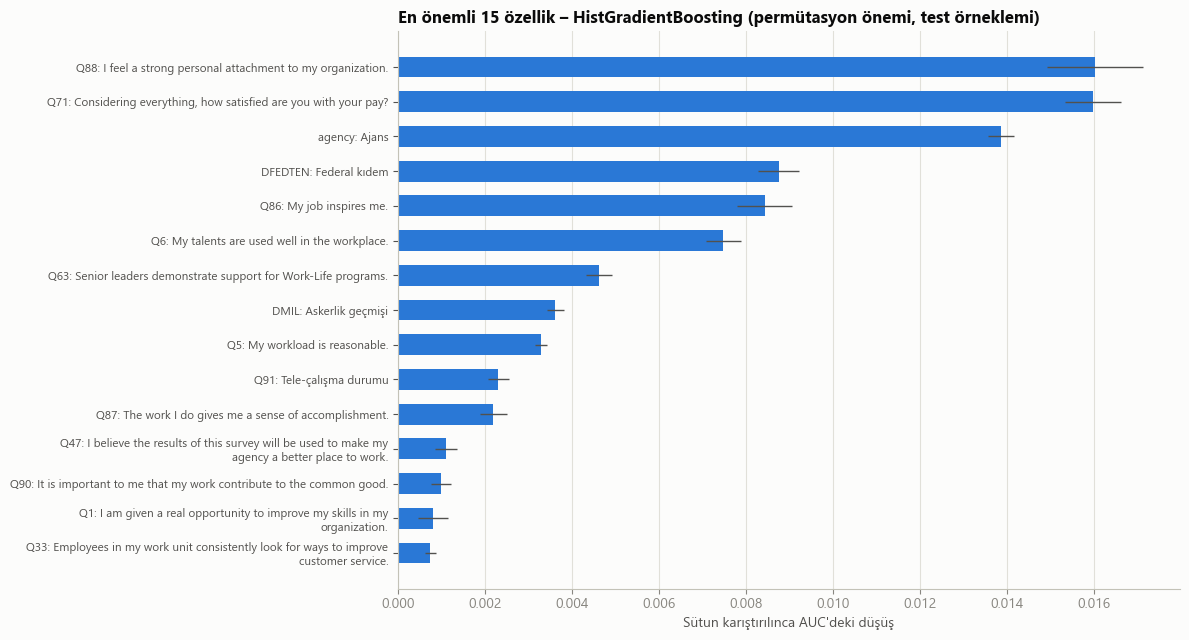

,AUC_düşüşü,ss,açıklama
Q88,0.0160,0.0011,I feel a strong personal attachment to my orga...
Q71,0.0160,0.0006,"Considering everything, how satisfied are you ..."
agency,0.0139,0.0003,Ajans
DFEDTEN,0.0088,0.0005,Federal kıdem
Q86,0.0084,0.0006,My job inspires me.
Q6,0.0075,0.0004,My talents are used well in the workplace.
Q63,0.0046,0.0003,Senior leaders demonstrate support for Work-Li...
DMIL,0.0036,0.0002,Askerlik geçmişi
Q5,0.0033,0.0001,My workload is reasonable.
Q91,0.0023,0.0002,Tele-çalışma durumu


In [16]:
ornek = X_te.sample(30_000, random_state=SEED).index
pi = permutation_importance(final[SECILEN], X_te.loc[ornek], y_te.loc[ornek], scoring="roc_auc",
                            sample_weight=w_te.loc[ornek].values, n_repeats=3, random_state=SEED, n_jobs=1)
onem = pd.DataFrame({"AUC_düşüşü": pi.importances_mean, "ss": pi.importances_std}, index=X_te.columns) \
         .sort_values("AUC_düşüşü", ascending=False)
ETIKET = {**text_map, "agency": "Ajans", "Q91": "Tele-çalışma durumu", "DRNO": "Irk", "DHISP": "Hispanik köken",
          "DDIS": "Engellilik", "DAGEGRP": "Yaş grubu (kuşak)", "DSUPER": "Yöneticilik", "DFEDTEN": "Federal kıdem",
          "DSEX": "Cinsiyet", "DMIL": "Askerlik geçmişi"}
onem["açıklama"] = onem.index.map(lambda c: ETIKET.get(c, c))
onem.to_csv(TAB / "06_permutasyon_onemi.csv")

t = onem.head(15)[::-1]
fig, ax = plt.subplots(figsize=(12, 6.5))
ax.barh([fill(f"{c}: {ETIKET.get(c, c)}", 70) for c in t.index], t["AUC_düşüşü"], xerr=t["ss"], color=SERIES[0], height=0.6,
        error_kw=dict(ecolor=INK2, lw=1))
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
ax.set_xlabel("Sütun karıştırılınca AUC'deki düşüş")
ax.set_title(f"En önemli 15 özellik – {SECILEN} (permütasyon önemi, test örneklemi)")
plt.tight_layout(); kaydet("06_04_permutasyon_onemi")
onem.head(15).round(4)

## 13. Kuşak analizi

**Önemli sınırlama:** Veri setinde doğum yılı yok; gizlilik nedeniyle yaş yalnızca **iki gruba** indirilmiş: "40 yaş altı" ve "40 ve üstü". Anket 2024'te yapıldığı için:
- **40 yaş altı** → yaklaşık 1985 sonrası doğumlu → **Y kuşağının (1981–1996) büyük kısmı + Z kuşağı (1997–2012)**
- **40 ve üstü** → yaklaşık 1984 öncesi doğumlu → **X kuşağı (1965–1980) + Baby Boomer (1946–1964) + Y'nin ilk yılları**

Yani kuşaklar **yaklaşık** olarak "Genç kuşak (Y/Z)" ve "Olgun kuşak (X/Boomer)" diye ikiye ayrılabiliyor. Daha ince bir ayrım için kıdem (DFEDTEN) ile birlikte bakılır.

Kuşak analizi dört soruya cevap verir:
1. Kuşaklar arasında ayrılma niyeti ve **nedenleri** farklı mı?
2. Model her iki kuşakta **eşit derecede iyi** çalışıyor mu? (adalet kontrolü)
3. Her kuşakta ayrılmayı **en çok etkileyen** sorular hangileri?
4. Kritik sorularda (maaş, ilham) kuşaklar farklı tepki veriyor mu?

In [17]:
# 13.1 Betimsel: tüm etiketli veri (model değil, ağırlıklı oranlar)
k = pd.DataFrame({"kuşak": KUSAK, "neden": df["DLEAVING"].astype(str), "w": w_all, "y": y_all, "kıdem": df["DFEDTEN"].astype(object)})
oran = k.groupby("kuşak").apply(lambda g: pd.Series({"n": len(g), "%_ayrılma": 100 * np.average(g.y, weights=g.w)}), include_groups=False)
neden = k.pivot_table(index="kuşak", columns="neden", values="w", aggfunc="sum")
neden = (100 * neden.div(neden.sum(axis=1), axis=0))[[c for c in df["DLEAVING"].cat.categories]]
kusak_betimsel = oran.join(neden.add_prefix("%_"))
display(kusak_betimsel.round(1))

kk = k[k["kıdem"].notna() & (k["kuşak"] != "Bilinmiyor (maskeli)")]
yas_kidem = kk.groupby(["kuşak", "kıdem"]).apply(lambda g: 100 * np.average(g.y, weights=g.w), include_groups=False).unstack()
yas_kidem = yas_kidem[[c for c in df["DFEDTEN"].cat.categories if c in yas_kidem.columns]]
yas_kidem_n = kk.groupby(["kuşak", "kıdem"]).size().unstack()[yas_kidem.columns]
print("Kuşak × federal kıdem – ayrılmayı düşünen % (ağırlıklı):"); display(yas_kidem.round(1))
print("Hücre büyüklükleri (n):"); display(yas_kidem_n)

,n,%_ayrılma,%_No,"%_Yes, other","%_Yes, to take another job within the Federal Government","%_Yes, to take another job outside the Federal Government"
kuşak,,,,,,
Bilinmiyor (maskeli),41592.0,44.4,55.6,15.0,24.4,5.0
Genç kuşak (<40: Y/Z),150776.0,38.6,61.4,7.6,24.5,6.5
Olgun kuşak (40+: X/Boomer),439930.0,35.4,64.6,14.0,18.3,3.1


Kuşak × federal kıdem – ayrılmayı düşünen % (ağırlıklı):


kıdem,Ten years or fewer,Eleven to 20 years,More than 20 years
kuşak,,,
Genç kuşak (<40: Y/Z),38.7,38.1,39.9
Olgun kuşak (40+: X/Boomer),33.8,35.4,37.1


Hücre büyüklükleri (n):


kıdem,Ten years or fewer,Eleven to 20 years,More than 20 years
kuşak,,,
Genç kuşak (<40: Y/Z),125009,25538,89
Olgun kuşak (40+: X/Boomer),137032,159693,142333


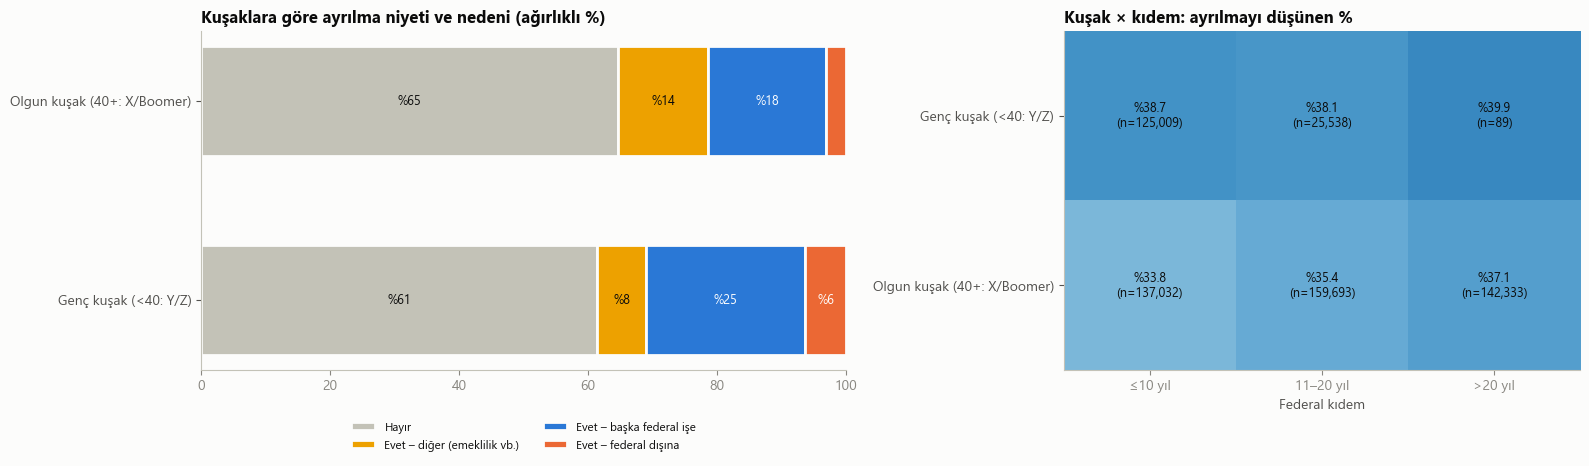

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
nn = neden.drop(index="Bilinmiyor (maskeli)", errors="ignore")
sol = 0
renk_neden = {"No": "#c3c2b7", "Yes, other": SERIES[3], "Yes, to take another job within the Federal Government": SERIES[0],
              "Yes, to take another job outside the Federal Government": SERIES[1]}
etiket_neden = {"No": "Hayır", "Yes, other": "Evet – diğer (emeklilik vb.)",
                "Yes, to take another job within the Federal Government": "Evet – başka federal işe",
                "Yes, to take another job outside the Federal Government": "Evet – federal dışına"}
left = np.zeros(len(nn))
for c in nn.columns:
    axes[0].barh(nn.index, nn[c], left=left, color=renk_neden[c], label=etiket_neden[c], height=0.55, edgecolor=SURFACE, linewidth=2)
    for i, v in enumerate(nn[c]):
        if v > 4:
            axes[0].text(left[i] + v / 2, i, f"%{v:.0f}", ha="center", va="center", fontsize=9,
                         color=INK if c in ("No", "Yes, other") else "white")
    left += nn[c].values
axes[0].set_xlim(0, 100); axes[0].grid(False); axes[0].legend(frameon=False, ncol=2, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
axes[0].set_title("Kuşaklara göre ayrılma niyeti ve nedeni (ağırlıklı %)")

im = axes[1].imshow(yas_kidem.values, cmap="Blues", vmin=20, vmax=50, aspect="auto"); axes[1].grid(False)
axes[1].set_xticks(range(yas_kidem.shape[1]), ["≤10 yıl", "11–20 yıl", ">20 yıl"])
axes[1].set_yticks(range(len(yas_kidem)), yas_kidem.index)
for i in range(yas_kidem.shape[0]):
    for j in range(yas_kidem.shape[1]):
        axes[1].text(j, i, f"%{yas_kidem.iat[i, j]:.1f}\n(n={yas_kidem_n.iat[i, j]:,})", ha="center", va="center", fontsize=9,
                     color="white" if yas_kidem.iat[i, j] > 40 else INK)
axes[1].set_xlabel("Federal kıdem"); axes[1].set_title("Kuşak × kıdem: ayrılmayı düşünen %")
plt.tight_layout(); kaydet("06_05_kusak_betimsel")

In [19]:
# 13.2 Adalet kontrolü: model her kuşakta ne kadar iyi?
kus_te = KUSAK.loc[idx_te].values
adalet = []
for g in ["Genç kuşak (<40: Y/Z)", "Olgun kuşak (40+: X/Boomer)", "Bilinmiyor (maskeli)"]:
    m = kus_te == g
    adalet.append({"kuşak": g, "n_test": int(m.sum()),
                   "ROC_AUC": roc_auc_score(yv[m], p_sec[m], sample_weight=wv[m]),
                   "gerçek_%ayrılma": 100 * np.average(yv[m], weights=wv[m]),
                   "tahmin_ort_%": 100 * np.average(p_sec[m], weights=wv[m]),
                   "duyarlılık": recall_score(yv[m], tahmin[m], sample_weight=wv[m]),
                   "kesinlik": precision_score(yv[m], tahmin[m], sample_weight=wv[m])})
adalet = pd.DataFrame(adalet).set_index("kuşak")
adalet.round(3)

,n_test,ROC_AUC,gerçek_%ayrılma,tahmin_ort_%,duyarlılık,kesinlik
kuşak,,,,,,
Genç kuşak (<40: Y/Z),30068,0.817,38.798,38.496,0.785,0.611
Olgun kuşak (40+: X/Boomer),88012,0.778,35.417,35.377,0.707,0.566
Bilinmiyor (maskeli),8380,0.796,44.074,44.707,0.827,0.604


,Genç kuşak (<40: Y/Z),Olgun kuşak (40+: X/Boomer),sıra_genç,sıra_olgun,açıklama
Q71,0.0197,0.0152,1,1,"Considering everything, how satisfied are you ..."
Q88,0.0160,0.0120,2,4,I feel a strong personal attachment to my orga...
agency,0.0110,0.0150,3,2,Ajans
DFEDTEN,0.0010,0.0129,14,3,Federal kıdem
Q86,0.0079,0.0078,4,5,My job inspires me.
Q6,0.0060,0.0062,5,6,My talents are used well in the workplace.
Q63,0.0054,0.0032,6,7,Senior leaders demonstrate support for Work-Li...
DMIL,0.0012,0.0032,12,8,Askerlik geçmişi
Q91,0.0015,0.0032,9,9,Tele-çalışma durumu
Q5,0.0022,0.0030,7,10,My workload is reasonable.


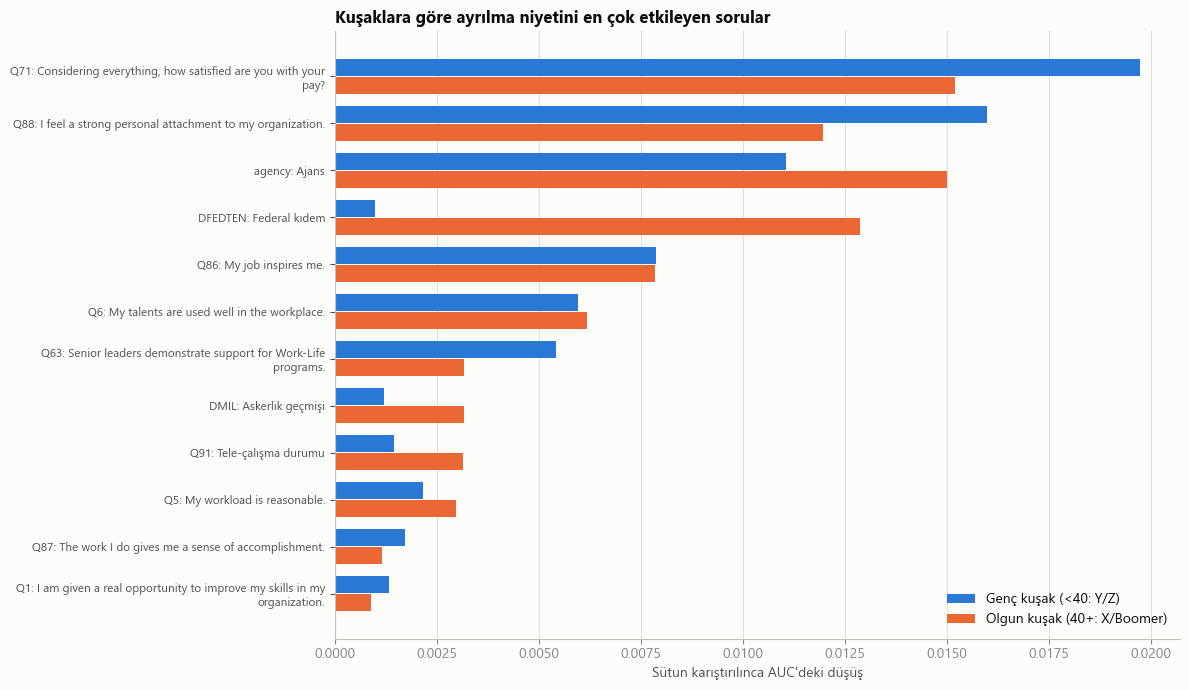

In [20]:
# 13.3 Her kuşakta ayrılmayı en çok etkileyen sorular (permütasyon önemi, test setinin ilgili kısmı)
kusak_onem = {}
for g in ["Genç kuşak (<40: Y/Z)", "Olgun kuşak (40+: X/Boomer)"]:
    ix = pd.Index(idx_te[kus_te == g])
    ix = ix.to_series().sample(min(20_000, len(ix)), random_state=SEED).index
    r = permutation_importance(final[SECILEN], X_te.loc[ix], y_te.loc[ix], scoring="roc_auc",
                               sample_weight=w_te.loc[ix].values, n_repeats=3, random_state=SEED, n_jobs=1)
    kusak_onem[g] = pd.Series(r.importances_mean, index=X_te.columns)
ko = pd.DataFrame(kusak_onem)
ko["sıra_genç"] = ko.iloc[:, 0].rank(ascending=False).astype(int)
ko["sıra_olgun"] = ko.iloc[:, 1].rank(ascending=False).astype(int)
ko["açıklama"] = ko.index.map(lambda c: ETIKET.get(c, c))
ko.to_csv(TAB / "06_kusak_onem.csv")
ust = ko.iloc[:, :2].max(axis=1).sort_values(ascending=False).head(12).index
display(ko.loc[ust].round(4))

t = ko.loc[ust[::-1]]
fig, ax = plt.subplots(figsize=(12, 7))
yy = np.arange(len(t))
ax.barh(yy + 0.19, t.iloc[:, 0], height=0.36, color=SERIES[0], label="Genç kuşak (<40: Y/Z)")
ax.barh(yy - 0.19, t.iloc[:, 1], height=0.36, color=SERIES[1], label="Olgun kuşak (40+: X/Boomer)")
ax.set_yticks(yy, [fill(f"{c}: {ETIKET.get(c, c)}", 62) for c in t.index], fontsize=8.5)
ax.grid(axis="y", visible=False); ax.legend(frameon=False, loc="lower right")
ax.set_xlabel("Sütun karıştırılınca AUC'deki düşüş")
ax.set_title("Kuşaklara göre ayrılma niyetini en çok etkileyen sorular")
plt.tight_layout(); kaydet("06_06_kusak_onem")

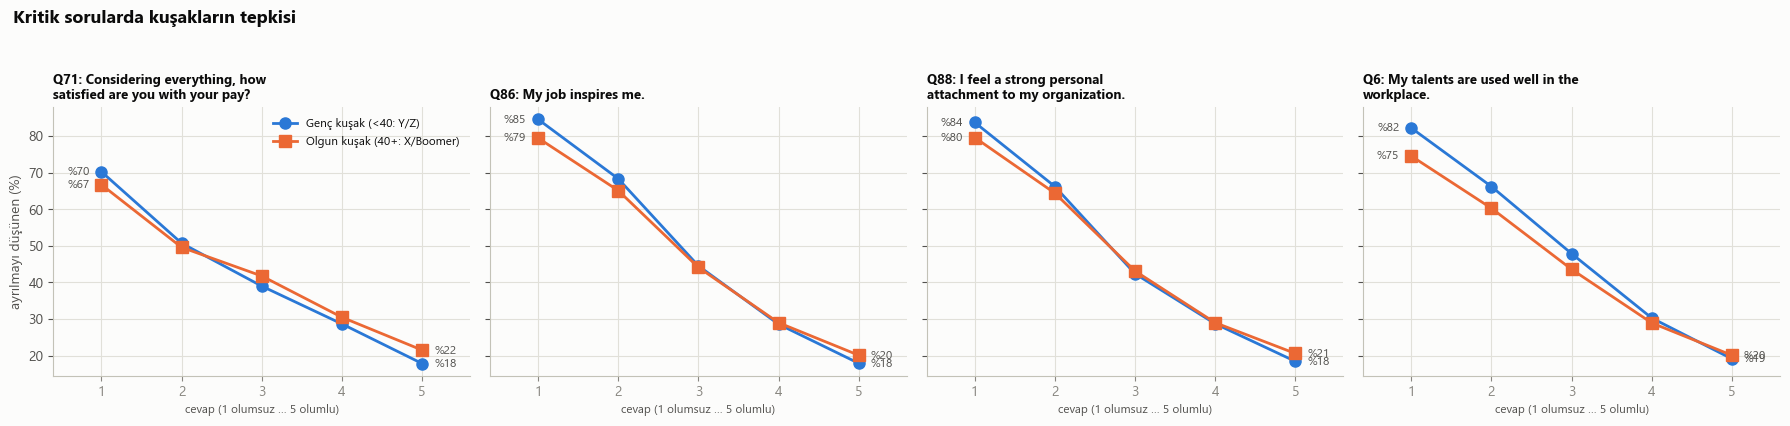

Q71                                               Q86  \
  Genç kuşak (<40: Y/Z) Olgun kuşak (40+: X/Boomer) Genç kuşak (<40: Y/Z)   
1                  70.2                        66.7                  84.5   
2                  50.7                        49.6                  68.3   
3                  39.0                        41.8                  44.5   
4                  28.7                        30.5                  28.6   
5                  17.9                        21.5                  17.9   

                                                Q88  \
  Olgun kuşak (40+: X/Boomer) Genç kuşak (<40: Y/Z)   
1                        79.4                  83.7   
2                        65.1                  66.2   
3                        44.1                  42.4   
4                        29.0                  28.7   
5                        20.1                  18.4   

                                                 Q6  \
  Olgun kuşak (40+: X/Boomer) Genç kuşak (<40: Y/Z)   
1                        79.6                  82.2   
2                        64.4                  66.2   
3                        43.1                  47.9   
4                        29.0                  30.3   
5                        20.6                  19.1   

                               
  Olgun kuşak (40+: X/Boomer)  
1                        74.5  
2                        60.2  
3                        43.6  
4                        28.9  
5                        20.1

In [21]:
# 13.4 Kritik sorulara kuşakların tepkisi: cevaba göre ayrılma oranı
SORULAR = ["Q71", "Q86", "Q88", "Q6"]
fig, axes = plt.subplots(1, len(SORULAR), figsize=(18, 4.3), sharey=True)
tepki = {}
for ax, q in zip(axes, SORULAR):
    for i, g in enumerate(["Genç kuşak (<40: Y/Z)", "Olgun kuşak (40+: X/Boomer)"]):
        m = (KUSAK == g) & df[q].notna()
        r = (y_all[m] * w_all[m]).groupby(df.loc[m, q].astype(int)).sum() / w_all[m].groupby(df.loc[m, q].astype(int)).sum() * 100
        tepki[(q, g)] = r
        ax.plot(r.index, r.values, color=SERIES[i], lw=2, marker="os"[i], ms=8, label=g)
        ax.text(5.15, r.values[-1], f"%{r.values[-1]:.0f}", color=INK2, fontsize=8.5, va="center")
        ax.text(0.85, r.values[0], f"%{r.values[0]:.0f}", color=INK2, fontsize=8.5, va="center", ha="right")
    ax.set_xticks([1, 2, 3, 4, 5]); ax.set_xlim(0.4, 5.6)
    ax.set_title(fill(f"{q}: {text_map[q]}", 36), fontsize=9.5); ax.set_xlabel("cevap (1 olumsuz … 5 olumlu)", fontsize=8.5)
axes[0].set_ylabel("ayrılmayı düşünen (%)"); axes[0].legend(frameon=False, fontsize=8.5, loc="upper right")
fig.suptitle("Kritik sorularda kuşakların tepkisi", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94]); kaydet("06_07_kusak_tepki")
pd.DataFrame(tepki).round(1)

## 14. Modeli kaydet ve eğitim–tahmin tutarlılığını test et
Ön işleme + model **tek bir Pipeline** olarak kaydedilir. Sonra diskten geri yüklenip, ham veriden `hazirla()` ile hazırlanan girdilerle **aynı tahminleri verdiği** doğrulanır. Böylece "eğitimde başka, kullanımda başka ön işleme" hatası olmaz.

> ⚠️ **Etik not:** FEVS anonim bir ankettir. Bu model **bireyleri işaretlemek, cezalandırmak veya takip etmek için değil**, grup düzeyinde "hangi koşullar ayrılma niyetini artırıyor?" sorusunu anlamak için kullanılmalıdır.

In [22]:
MODEL_YOLU = MODELS / "ayrilma_modeli.joblib"
joblib.dump({"pipeline": final[SECILEN], "esik": ESIK, "ozellikler": FEATURES, "num": NUM, "cat": CAT,
             "model_adi": SECILEN, "seed": SEED, "test_parmak_izi": TEST_HASH}, MODEL_YOLU)
print(f"Kaydedildi: {MODEL_YOLU}  ({MODEL_YOLU.stat().st_size / 1e6:.1f} MB)")

paket = joblib.load(MODEL_YOLU)
ham = df.loc[idx_te[:500]]                              # ham satırlar (henüz hazırlanmamış)
p_yeniden = paket["pipeline"].predict_proba(hazirla(ham, paket["num"], paket["cat"]))[:, 1]
assert np.allclose(p_yeniden, p_sec[:500]), "Kaydedilen model farklı tahmin veriyor!"
print("✓ Geri yüklenen model, bellekteki modelle birebir aynı tahminleri veriyor.")

Kaydedildi: ~\fevs_proje\models\ayrilma_modeli.joblib  (0.7 MB)
✓ Geri yüklenen model, bellekteki modelle birebir aynı tahminleri veriyor.


## 15. Sonuçların özeti (README için)

In [23]:
ozet = {
    "veri": {"etiketli_satir": int(len(df)), "etiketsiz_cikarilan": int(etiketsiz), "train": int(len(idx_tr)), "test": int(len(idx_te)),
             "ozellik_sayisi": len(FEATURES), "ayrilma_orani_agirlikli": float(np.average(y_all, weights=w_all)),
             "test_parmak_izi": TEST_HASH},
    "ayar": {"orneklem": N_TUNE, "deneme_sayisi": N_ITER, "cv_kat": N_FOLD},
    "cv": {k: {"auc": float(v["cv_auc"]), "ss": float(v["cv_ss"]), "sure_sn": float(v["sure_sn"]),
               "parametreler": {p: (float(x) if isinstance(x, (float, np.floating)) else x) for p, x in v["parametreler"].items()}}
           for k, v in en_iyi.items()},
    "secilen_model": SECILEN, "cv_lideri": lider, "esik": ESIK,
    "test": test_tab.round(4).to_dict(orient="index"),
    "esik_metrikleri": esik_tab.round(4).to_dict(),
    "sizinti_deneyi": SIZINTI,
    "onem_ilk10": onem.head(10)[["AUC_düşüşü", "açıklama"]].round(4).to_dict(orient="index"),
    "kusak_betimsel": kusak_betimsel.round(2).to_dict(orient="index"),
    "kusak_kidem": yas_kidem.round(2).to_dict(orient="index"),
    "kusak_adalet": adalet.round(4).to_dict(orient="index"),
    "kusak_onem_ilk8": {g: ko[g].sort_values(ascending=False).head(8).round(4).to_dict() for g in kusak_onem},
    "kusak_tepki": {f"{q} | {g}": r.round(1).to_dict() for (q, g), r in tepki.items()},
}
(TAB / "06_model_ozeti.json").write_text(json.dumps(ozet, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print(json.dumps({k: ozet[k] for k in ["secilen_model", "cv_lideri", "esik", "sizinti_deneyi"]}, ensure_ascii=False, indent=2))

{
  "secilen_model": "HistGradientBoosting",
  "cv_lideri": "LightGBM",
  "esik": 0.3200000000000002,
  "sizinti_deneyi": {
    "Q46/Q70/Q72 olmadan": 0.7771894080940788,
    "Q46/Q70/Q72 ile": 0.7914047511535207
  }
}
